Apply LIME (Local Interpretable Model-Agnostic Explanations) for explaining individual model predictions, generating interpretable surrogate models to enhance trust in black-box classifiers.

In [1]:
import pandas as pd
import numpy as np

In [2]:

np.random.seed(42)

In [3]:
n_samples = 1000

In [4]:
age = np.random.normal(60, 12, n_samples).clip(20, 90).round(1)
bmi = np.random.normal(28, 5, n_samples).clip(16, 45).round(1)
systolic_bp = np.random.normal(135, 18, n_samples).clip(90, 200).round(1)
troponin = np.random.exponential(scale=0.5, size=n_samples).clip(0.01, 5.0).round(3)
creatinine = np.random.normal(1.1, 0.4, n_samples).clip(0.4, 4.0).round(2)
glucose = np.random.normal(110, 30, n_samples).clip(70, 300).round(1)

In [5]:
logits = (
    -4.0
    + 0.04 * (age - 60)
    + 0.05 * (bmi - 25)
    + 0.02 * (systolic_bp - 120)
    + 2.10 * troponin
    + 0.75 * (creatinine ** 2)
    + 0.012 * (glucose - 100)
)

In [6]:
probs = 1 / (1 + np.exp(-logits))
adverse_event = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [7]:
df_lime = pd.DataFrame({
    'age': age,
    'bmi': bmi,
    'systolic_bp': systolic_bp,
    'troponin': troponin,
    'creatinine': creatinine,
    'glucose': glucose,
    'adverse_event': adverse_event
})

In [8]:
print("Dataset Shape:", df_lime.shape)
print("Adverse Event Target Breakdown:\n", df_lime['adverse_event'].value_counts(normalize=True).round(3))

Dataset Shape: (1000, 7)
Adverse Event Target Breakdown:
 adverse_event
0    0.742
1    0.258
Name: proportion, dtype: float64


In [9]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

In [10]:
X = df_lime.drop(columns=['adverse_event'])
y = df_lime['adverse_event']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
black_box_model = HistGradientBoostingClassifier(max_iter=150, random_state=42)
black_box_model.fit(X_train_scaled, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

HistGradientBoostingClassifier(max_iter=150, random_state=42)

In [14]:
auc_score = roc_auc_score(y_test, black_box_model.predict_proba(X_test_scaled)[:, 1])
print(f"Black-Box Classifier Out-of-Sample ROC-AUC Score: {auc_score:.4f}")

Black-Box Classifier Out-of-Sample ROC-AUC Score: 0.7592


In [ ]:
def explain_instance_lime(model, instance, feature_names, n_samples=2000, kernel_width=1.0, random_state=42):
    """
    Generates local linear surrogate explanations (LIME) for a single instance prediction.
    """
    np.random.seed(random_state)
    
    num_features = len(instance)
    perturbations = np.random.normal(0, 1, size=(n_samples, num_features))
    perturbed_instances = instance + perturbations * 0.5  # Local neighborhood sampling
    
    distances = np.linalg.norm(perturbed_instances - instance, axis=1)
    weights = np.exp(-(distances ** 2) / (kernel_width ** 2))
    
    target_probs = model.predict_proba(perturbed_instances)[:, 1]
    
    surrogate_model = Ridge(alpha=1.0, random_state=random_state)
    surrogate_model.fit(perturbed_instances, target_probs, sample_weight=weights)
    
    local_importance = surrogate_model.coef_
    local_intercept = surrogate_model.intercept_
    
    df_explanation = pd.DataFrame({
        'Feature': feature_names,
        'Instance Value': instance,
        'Local Weight': local_importance
    }).sort_values(by='Local Weight', key=abs, ascending=True)
    
    return df_explanation, local_intercept

In [16]:
patient_idx = 5
test_patient_scaled = X_test_scaled[patient_idx]
test_patient_raw = X_test.iloc[patient_idx]

In [17]:
bb_pred_prob = black_box_model.predict_proba([test_patient_scaled])[0, 1]
actual_label = y_test.iloc[patient_idx]

In [18]:
print(f"--- LIME Explanation for Patient Test Instance #{patient_idx} ---")
print(f"Actual Clinical Status : {'Adverse Event' if actual_label == 1 else 'Stable'}")
print(f"Black-Box Model Risk  : {bb_pred_prob:.2%}")

--- LIME Explanation for Patient Test Instance #5 ---
Actual Clinical Status : Stable
Black-Box Model Risk  : 2.78%


In [19]:
df_explanation, intercept = explain_instance_lime(
    black_box_model, 
    test_patient_scaled, 
    X.columns.tolist()
)

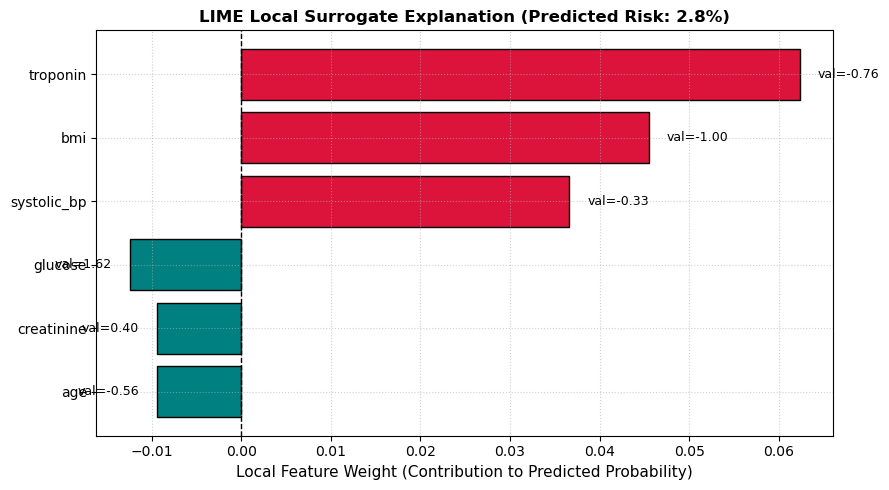

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = ['crimson' if w > 0 else 'teal' for w in df_explanation['Local Weight']]
bars = ax.barh(df_explanation['Feature'], df_explanation['Local Weight'], color=colors, edgecolor='black')

ax.set_title(f"LIME Local Surrogate Explanation (Predicted Risk: {bb_pred_prob:.1%})", fontsize=12, fontweight='bold')
ax.set_xlabel("Local Feature Weight (Contribution to Predicted Probability)", fontsize=11)
ax.axvline(0, color='black', linestyle='--', lw=1)
ax.grid(True, linestyle=':', alpha=0.6)

# Annotate bar labels with raw feature values
for bar, raw_val in zip(bars, df_explanation['Instance Value']):
    width = bar.get_width()
    offset = 0.002 if width >= 0 else -0.002
    ha = 'left' if width >= 0 else 'right'
    ax.text(width + offset, bar.get_y() + bar.get_height()/2, f"val={raw_val:.2f}", va='center', ha=ha, fontsize=9)

plt.tight_layout()
plt.show()